# Введение в ИИ. Коллоквиум. Компьютерная часть

Привет! Это компьютерная часть коллоквиума. На неё отводится 30 минут.

Задания разделены на 2 части:

1. **[6 баллов]** Подготовка данных и классификация с помощью `scikit-learn`.

2. **[4 балла]** Градиентный спуск: реализация и эксперименты с темпом обучения.

**Правила**:

* в ячейках ниже напиши или допиши код, а там, где требуется — текст;
* перед сдачей повторно выполни все ячейки;
* для сдачи загрузи в LMS своё решение в виде файла формата .ipynb.

**Можно пользоваться**:

* Google Colab или Jupyter Notebook;
* библиотеками numpy, pandas, matplotlib, seaborn и scikit-learn;
* официальной документацией к этим библиотекам: [numpy](https://numpy.org/doc/stable/), [pandas](https://pandas.pydata.org/docs/), [matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [scikit-learn](https://scikit-learn.org/stable/).

**Нельзя пользоваться**:

* другими средами разработки и библиотеками;
* нейросетями, в том числе в Colab;
* телефоном;
* посторонними вкладками, в том числе поисковыми системами;
* файлами, кроме этого ноутбука и датасетов, на которые он ссылается;
* бумажными записями;
* чужим решением.

**Решение оценивается в 0 баллов, если**:

* в коде содержится готовый ответ;
* вывод ячеек не соответствует написанному коду.

## Часть 1 [6 баллов] Айсберг прямо по курсу

В этой части поработаем с датасетом Titanic, в котором собрана информация о пассажирах «Титаника». Таргет — бинарная величина `survived`: 1, если пассажир выжил, и 0, если нет.

### Описание датасета

survived — выжил ли пассажир (0 — нет, 1 — да), целевая переменная.

pclass — класс билета (1 — первый, 2 — второй, 3 — третий).

sex — пол (male или female).

age — возраст.

sibsp — число братьев, сестёр и супругов на борту.

parch — число родителей и детей на борту.

fare — стоимость билета.

embarked — порт посадки (S — Саутгемптон, C — Шербур, Q — Куинстаун).

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = sns.load_dataset("titanic")

# Оставим только нужные столбцы: в остальных есть копии таргета (например, alive) и других признаков
df = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]

display(df.head())
print(df.shape)

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


(891, 8)


### Задание 1 [2 балла]

Подготовь данные к обучению.

1. Выведи долю пропусков в каждом столбце **[0,5 балла]**

In [13]:
# Твой код
df.isna().mean()

survived    0.000000
pclass      0.000000
sex         0.000000
age         0.198653
sibsp       0.000000
parch       0.000000
fare        0.000000
embarked    0.002245
dtype: float64

2. Заполни пропуски в `age` и `embarked`. Объясни, почему ты выбрал именно такой способ **[0,5 балла]**

In [14]:
# Твой код
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [15]:
df['age_missing'] = df['age'].isna().astype(int)

df['age'] = df.groupby(['pclass', 'sex'])['age'].transform(
    lambda group: group.fillna(group.median())
)

embarked почти целиком заполнен, так что вне зависимости от того, возьмем мы заполним модой или удалим эти строки все будет хорошо

С возрастом у нас интереснее: примерно 20% возрастов не заполнены. Заполнять средним будет плохо и так себе повлияет на дисперсию, так что мы заполняем средним опираясь на комбинацию класса пассажира и его пола.

3. Закодируй категориальные признаки `sex` и `embarked` с помощью One-Hot Encoding **[0,5 балла]**

In [26]:
# Твой код
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ct = ColumnTransformer(
    [
        ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ['sex', 'embarked']),
    ],
    remainder='passthrough',
    verbose_feature_names_out=False,
)
ct.set_output(transform='pandas')

df_encoded = ct.fit_transform(df)
display(df_encoded)


,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,survived,pclass,age,sibsp,parch,fare,age_missing
0,0.0,1.0,0.0,0.0,1.0,0,3,22.0,1,0,7.2500,0
1,1.0,0.0,1.0,0.0,0.0,1,1,38.0,1,0,71.2833,0
2,1.0,0.0,0.0,0.0,1.0,1,3,26.0,0,0,7.9250,0
3,1.0,0.0,0.0,0.0,1.0,1,1,35.0,1,0,53.1000,0
4,0.0,1.0,0.0,0.0,1.0,0,3,35.0,0,0,8.0500,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0.0,1.0,0.0,0.0,1.0,0,2,27.0,0,0,13.0000,0
887,1.0,0.0,0.0,0.0,1.0,1,1,19.0,0,0,30.0000,0
888,1.0,0.0,0.0,0.0,1.0,0,3,21.5,1,2,23.4500,1
889,0.0,1.0,1.0,0.0,0.0,1,1,26.0,0,0,30.0000,0


4. Отдели таргет от признаков и раздели данные на обучающую и тестовую выборки в отношении 75 к 25 с `stratify=y` **[0,5 балла]**

In [17]:

random_state = 42

# Твой код

### Задание 2 [4 балла]

Теперь обучи модель классификации.

1. Обучи логистическую регрессию `LogisticRegression(max_iter=1000)` на обучающей выборке и посчитай Accuracy на тестовой. Сравни её с константной моделью, которая всем предсказывает самый частый класс обучающей выборки **[1 балл]**

In [18]:

# Твой код

2. С помощью `predict_proba` получи вероятности выживания для тестовой выборки. Посчитай Accuracy, Precision и Recall при порогах $0{,}3$, $0{,}5$ и $0{,}7$ и выведи их в одной таблице **[2 балла]**

In [19]:
# Твой код

3. Как меняются Precision и Recall с ростом порога? Объясни, почему так происходит **[1 балл]**

Твой ответ

## Часть 2 [4 балла] Шаг вперёд, два назад

### Задание 3 [4 балла]

Ниже дана функция двух переменных:

$$
g(x, y) = (x - 2)^2 + 4(y + 1)^2.
$$

Исследуй, как темп обучения влияет на работу градиентного спуска.

1. Допиши функцию `gradient_descent`: она должна сделать `n_iter` шагов градиентного спуска из точки `z0` с темпом обучения `learning_rate` и вернуть массив всех точек траектории **[1,5 балла]**

In [20]:
def g(z):
    x, y = z
    return (x - 2) ** 2 + 4 * (y + 1) ** 2


def grad_g(z):
    x, y = z
    return np.array([2 * (x - 2), 8 * (y + 1)])


def gradient_descent(grad, z0, learning_rate, n_iter):
    # твой код
    pass

2. Запусти алгоритм из точки $(6, 4)$ на 30 итераций с тремя значениями темпа обучения: $0{,}05$, $0{,}2$ и $0{,}6$. Для каждого значения выведи полученную точку и значение функции в ней. Траекторию сохрани в словарь `paths`: при помощи него ниже построй графики координаты `y` по итерациям **[1 балл]**

In [21]:
learning_rates = [0.05, 0.2, 0.6]
z0 = np.array([6.0, 4.0])
paths = {}

# Твой код

KeyError: 0.05

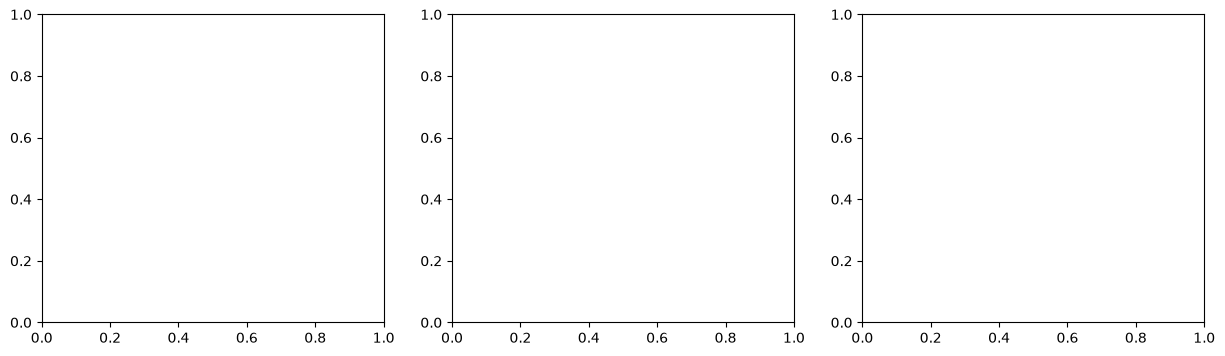

In [22]:
# Готовый код для графика, менять его не нужно
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    ax.plot(paths[lr][:, 1], marker="o", markersize=3)
    ax.set_title(f"Темп обучения {lr}")
    ax.set_xlabel("Итерация")
    ax.set_ylabel("y")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3. Напиши выводы: что происходит при каждом значении темпа обучения и почему? **[1,5 балла]**

Твой ответ